# 01. Orientation from the gyroscope

This notebook estimates how the MVSEC hexacopter rotates during the `indoor_flying4` flight using only its gyroscope, and compares the result with motion-capture ground truth.

A gyroscope measures angular velocity in the sensor's own frame. If the orientation at one instant is known, multiplying it by the small rotation the gyro reports over the next millisecond gives the orientation a millisecond later. Repeating this 20,000 times reconstructs the full rotation history. The only quantity that must be removed first is the gyro bias, a constant offset that would otherwise add a steady spin to the estimate.

In [1]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path.cwd().parent))
from imu_tracking import data, evaluation, integration, plots

# Folder holding the MVSEC bags. Change this to wherever you downloaded them.
DATA_DIR = Path.home() / "Developer/Projects/event-vision-toolkit/data/raw/mvsec"
SEQUENCE_NAME = "indoor_flying4"
CALIBRATION_PATH = Path("../calibration/camchain_imucam_indoor_flying.yaml")
CACHE_PATH = Path(f"../data/{SEQUENCE_NAME}.npz")
FIGURE_DIR = Path("../figures")

# The hexacopter rests on the floor for about 3.5 s before the propellers spin up
STATIC_DURATION = 3.0

FIGURE_DIR.mkdir(exist_ok=True)
plots.use_paper_style()

## Data

MVSEC records the DAVIS 346 IMU at 1 kHz and the camera pose from a motion-capture system. The IMU axes match the camera axes (x right, y down, z forward) up to a 1 degree rotation given in the calibration file.

In [2]:
sequence = data.load_sequence(
    DATA_DIR / f"{SEQUENCE_NAME}_data.bag",
    DATA_DIR / f"{SEQUENCE_NAME}_gt.bag",
    CACHE_PATH,
)
camera_from_imu_rotation, imu_origin_in_camera = data.load_imu_to_camera_extrinsics(CALIBRATION_PATH)

imu_time = sequence["imu_time"] - sequence["imu_time"][0]
accel = sequence["accel"]
gyro = sequence["gyro"]

imu_rate = 1 / np.median(np.diff(imu_time))
ground_truth_rate = 1 / np.median(np.diff(sequence["ground_truth_time"]))
print(f"IMU samples:          {len(imu_time)} at {imu_rate:.0f} Hz over {imu_time[-1]:.1f} s")
print(f"Ground-truth poses:   {len(sequence['ground_truth_time'])} at {ground_truth_rate:.0f} Hz")

IMU samples:          19862 at 1001 Hz over 19.8 s
Ground-truth poses:   1697 at 91 Hz


## Bias and world frame

The first three seconds are used as a bias window because the hexacopter is still on the floor. The gyro mean over that window is the gyro bias. The accelerometer mean gives the direction of gravity, which fixes roll and pitch. Yaw cannot be observed from gravity, so the world x axis is defined as the camera's initial forward direction projected onto the floor.

The ground truth is expressed in the first camera frame, which is tilted because the camera looks down at the floor. Rotating it into the gravity-aligned world frame makes "up" mean up in every plot.

In [3]:
static_result = data.estimate_static_biases(sequence, STATIC_DURATION)
gyro_bias = static_result["gyro_bias"]
accel_bias = static_result["accel_bias"]

world_from_first_camera = data.build_world_frame(static_result["up_direction_in_imu"], camera_from_imu_rotation)
camera_tilt = np.degrees(np.arccos(np.dot(world_from_first_camera[2], [0.0, -1.0, 0.0])))

time_offset = data.estimate_ground_truth_time_offset(sequence, camera_from_imu_rotation)
ground_truth_time, ground_truth_positions, ground_truth_rotations = data.ground_truth_imu_poses(
    sequence, world_from_first_camera, camera_from_imu_rotation, imu_origin_in_camera, time_offset
)
ground_truth_time = ground_truth_time - sequence["imu_time"][0]

# MVSEC ground truth starts at the identity, so the first IMU pose follows from the frame choice alone
initial_rotation = world_from_first_camera @ camera_from_imu_rotation
initial_position = ground_truth_positions[0]
imu_from_body_rotation = initial_rotation.T

print(f"|accel| at rest:      {static_result['mean_accel_magnitude']:.3f} m/s^2 (gravity is 9.81)")
print(f"accel std at rest:    {np.round(static_result['accel_std_at_rest'], 3)} m/s^2")
print(f"gyro bias:            {np.round(gyro_bias, 4)} rad/s")
print(f"camera tilt at rest:  {camera_tilt:.1f} deg below horizontal")
print(f"ground-truth offset:  {time_offset * 1000:.1f} ms")

|accel| at rest:      8.771 m/s^2 (gravity is 9.81)
accel std at rest:    [0.106 0.233 0.146] m/s^2
gyro bias:            [-0.0151 -0.0224 -0.0099] rad/s
camera tilt at rest:  16.9 deg below horizontal
ground-truth offset:  -57.5 ms


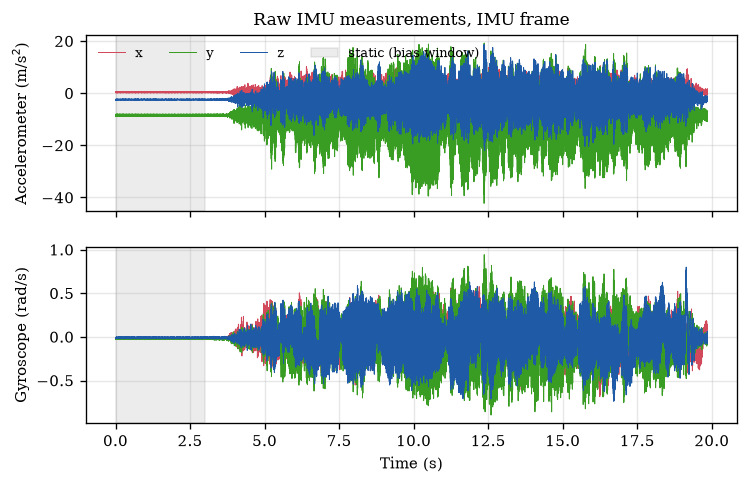

In [4]:
figure = plots.plot_raw_imu(imu_time, accel, gyro, STATIC_DURATION)
figure.savefig(FIGURE_DIR / "raw_imu.png")
plt.show()

## Integrating the gyroscope

In [5]:
gyro_rotations = integration.integrate_gyro(imu_time, gyro, gyro_bias, initial_rotation)

matched_indices = evaluation.nearest_indices(imu_time, ground_truth_time)
gyro_rotation_error = evaluation.rotation_errors_degrees(gyro_rotations[matched_indices], ground_truth_rotations)

ground_truth_ypr = evaluation.body_euler_degrees(ground_truth_rotations, imu_from_body_rotation)
gyro_ypr = evaluation.body_euler_degrees(gyro_rotations, imu_from_body_rotation)

print(f"Rotation error, gyro only: mean {gyro_rotation_error.mean():.2f} deg, "
      f"final {gyro_rotation_error[-1]:.2f} deg, max {gyro_rotation_error.max():.2f} deg")

Rotation error, gyro only: mean 0.26 deg, final 0.76 deg, max 0.96 deg


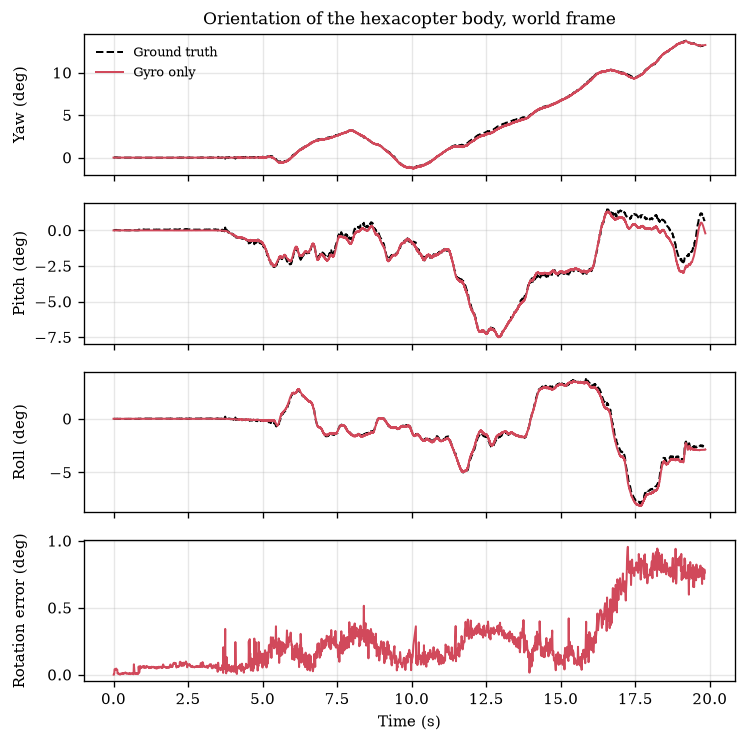

In [6]:
estimates = {"Gyro only": (imu_time, gyro_ypr, gyro_rotation_error)}
figure = plots.plot_orientation(ground_truth_time, ground_truth_ypr, estimates)
figure.savefig(FIGURE_DIR / "orientation_gyro_only.png")
plt.show()

## What this shows

Figure `orientation_gyro_only.png` overlays the integrated gyro (red) on the ground truth (dashed black). The two curves are almost indistinguishable over the 20 s flight, and the error panel stays below one degree. Orientation is the part of the motion an IMU measures well, because the gyro is integrated once and its bias was removed before take-off.

Position is a different problem. Notebook 02 shows why.